# Phase 5 - Exploratory Data Analysis

Project: **Sentiment Analysis with Facebook**

Distributions, text length, sentiment by category, trend and label consistency.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
from src import config
from src.data.load_data import load_raw, inspect_dataset
from src.data.preprocess import prepare_dataframe, clean_text
prep_df = pd.read_csv(config.DATA_PROCESSED / 'prepared_dataset.csv', parse_dates=['timestamp'])

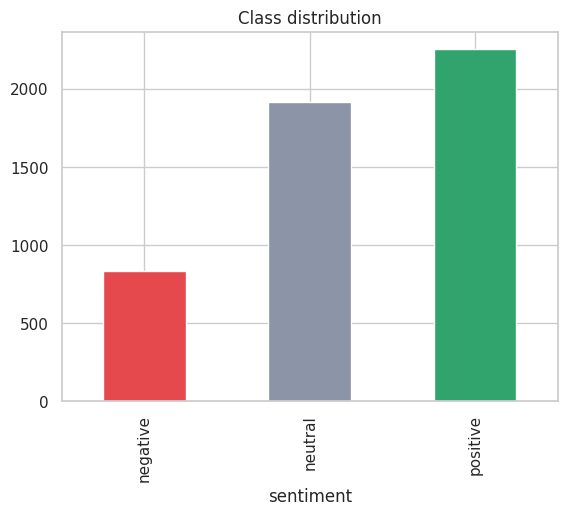

In [2]:
prep_df['sentiment'].value_counts().reindex(config.LABELS).plot(kind='bar', color=['#e5484d','#8b95a7','#30a46c'], title='Class distribution')
plt.show()

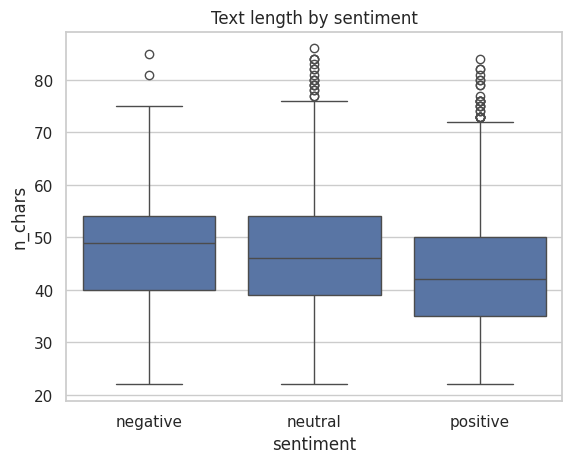

In [3]:
prep_df['n_chars'] = prep_df['text'].str.len()
sns.boxplot(data=prep_df, x='sentiment', y='n_chars', order=config.LABELS)
plt.title('Text length by sentiment'); plt.show()

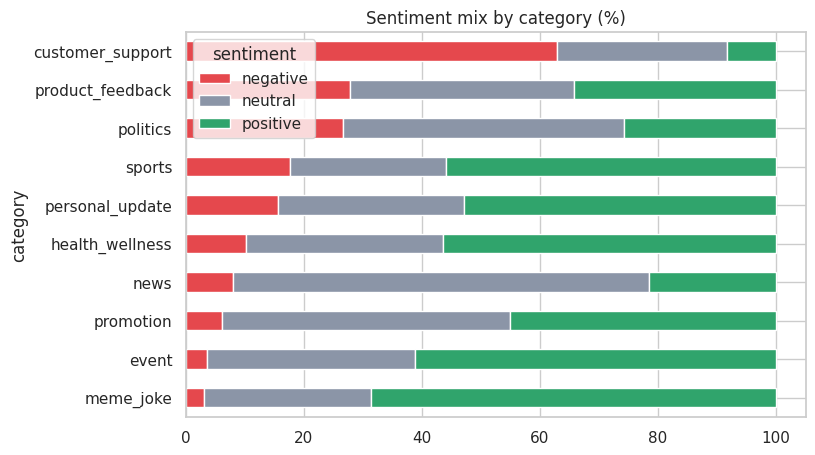

In [4]:
ct = pd.crosstab(prep_df['category'], prep_df['sentiment'], normalize='index')[config.LABELS] * 100
ct.sort_values('negative').plot(kind='barh', stacked=True, color=['#e5484d','#8b95a7','#30a46c'], figsize=(8,5))
plt.title('Sentiment mix by category (%)'); plt.show()

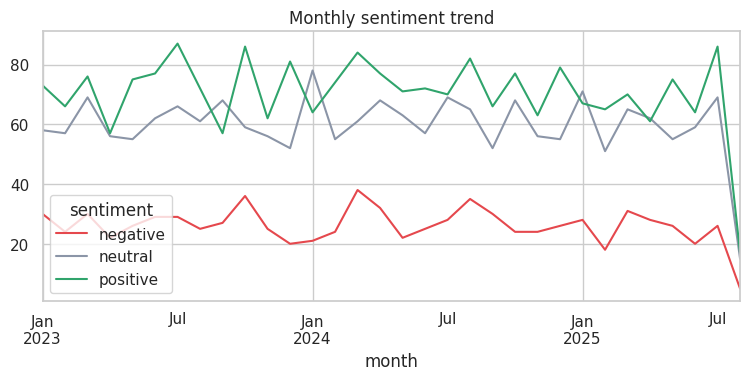

In [5]:
m = prep_df.assign(month=prep_df['timestamp'].dt.to_period('M').dt.start_time).pivot_table(index='month', columns='sentiment', values='text', aggfunc='count', fill_value=0)[config.LABELS]
m.plot(figsize=(9,3.5), color=['#e5484d','#8b95a7','#30a46c'], title='Monthly sentiment trend'); plt.show()

In [6]:
from src.analysis.keywords import common_words
for lab in config.LABELS:
    print(lab, [w['word'] for w in common_words(prep_df, 8, lab)])

negative ['new', 'please', 'day', 'request', 'update', 'stark', 'app', 'crashing']
neutral ['new', 'update', 'day', 'smartwatch', 'headphones', 'sneakers', 'policy', 'laptop']
positive ['new', 'day', 'feeling', 'health', 'tech', 'work', 'goals', 'missed']
